In [1]:
# Customer Risk Intelligence
# 02 - Baseline Machine Learning & SHAP Explainability

print("Baseline ML and SHAP analysis")

Baseline ML and SHAP analysis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import shap

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
DATA_PATH = Path("../data/raw/telco_customer_churn.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [4]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Convert target to binary
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

print("Features:", X.shape[1])
print("Target:", y.shape)

Features: 19
Target: (7043,)


In [6]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\Sudeen\AppData\Local\Temp\ipykernel_25700\1929721838.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (5634, 19)
Testing set: (1409, 19)


In [8]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [9]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [11]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [12]:
lr_predictions = logistic_model.predict(X_test)

lr_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

Predictions generated.


In [13]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [14]:
rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

Predictions generated.


In [15]:
def evaluate_model(y_true, predictions, probabilities, model_name):

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions),
        "ROC_AUC": roc_auc_score(y_true, probabilities)
    }

    return results

In [16]:
model_results = pd.DataFrame([
    evaluate_model(
        y_test,
        lr_predictions,
        lr_probabilities,
        "Logistic Regression"
    ),
    evaluate_model(
        y_test,
        rf_predictions,
        rf_probabilities,
        "Random Forest"
    )
])

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
1,Random Forest,0.7658,0.5521,0.6230,0.5854,0.8218


In [17]:
print("LOGISTIC REGRESSION")
print("=" * 60)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["No Churn", "Churn"]
    )
)

print("\nRANDOM FOREST")
print("=" * 60)

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["No Churn", "Churn"]
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



In [18]:
lr_cm = confusion_matrix(
    y_test,
    lr_predictions
)

rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)

print("Logistic Regression confusion matrix:")
print(lr_cm)

print("\nRandom Forest confusion matrix:")
print(rf_cm)

Logistic Regression confusion matrix:
[[926 109]
 [165 209]]

Random Forest confusion matrix:
[[846 189]
 [141 233]]


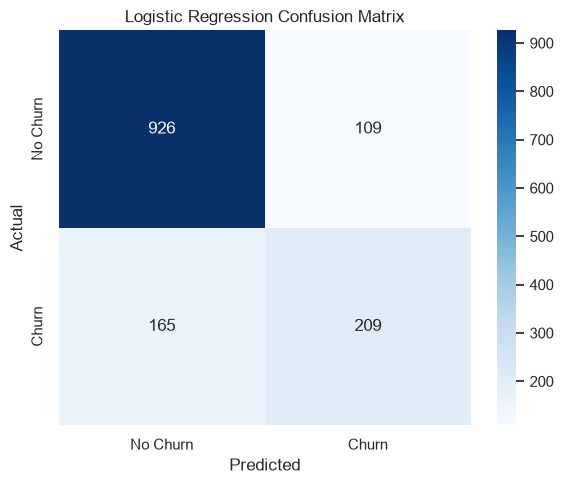

In [19]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

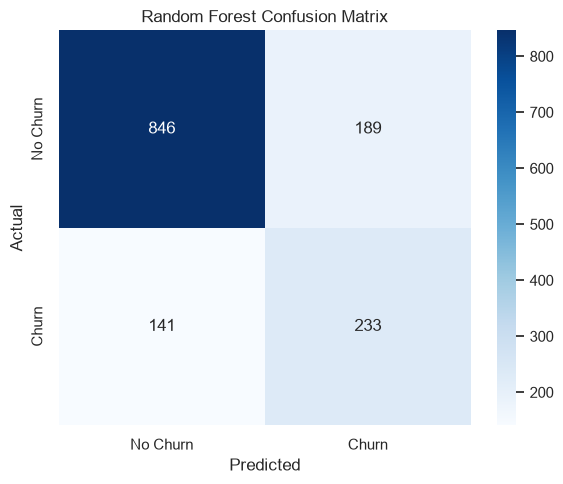

In [20]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [21]:
rf_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

rf_classifier = random_forest_model.named_steps[
    "classifier"
]

print("Random Forest components extracted.")

Random Forest components extracted.


In [22]:
X_train_transformed = rf_preprocessor.transform(
    X_train
)

X_test_transformed = rf_preprocessor.transform(
    X_test
)

print("Transformed training shape:", X_train_transformed.shape)
print("Transformed testing shape:", X_test_transformed.shape)

Transformed training shape: (5634, 45)
Transformed testing shape: (1409, 45)


In [23]:
feature_names = rf_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

feature_names[:20]

Number of transformed features: 45


array(['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges',
       'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male',
       'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No',
       'cat__Dependents_Yes', 'cat__PhoneService_No',
       'cat__PhoneService_Yes', 'cat__MultipleLines_No',
       'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes',
       'cat__InternetService_DSL', 'cat__InternetService_Fiber optic',
       'cat__InternetService_No', 'cat__OnlineSecurity_No',
       'cat__OnlineSecurity_No internet service'], dtype=object)

In [24]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
3,num__TotalCharges,0.142474
1,num__tenure,0.132329
2,num__MonthlyCharges,0.122295
36,cat__Contract_Month-to-month,0.072302
18,cat__OnlineSecurity_No,0.036642
38,cat__Contract_Two year,0.036527
27,cat__TechSupport_No,0.031064
43,cat__PaymentMethod_Electronic check,0.029037
16,cat__InternetService_Fiber optic,0.028522
21,cat__OnlineBackup_No,0.016718


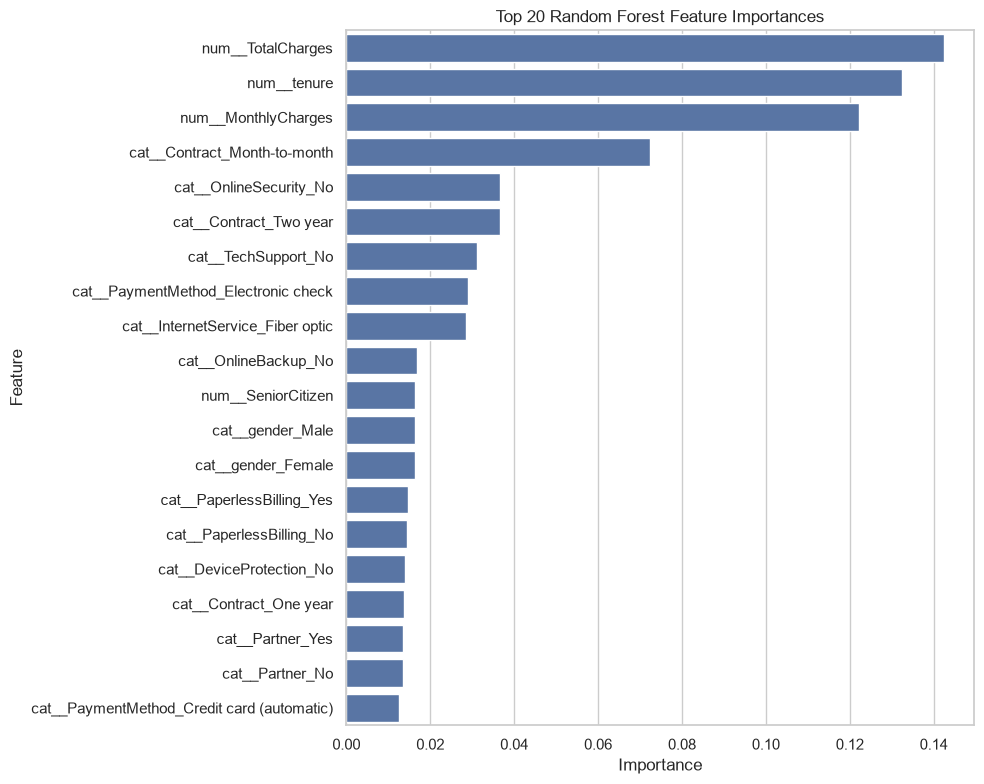

In [25]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [26]:
explainer = shap.TreeExplainer(
    rf_classifier
)

print("SHAP TreeExplainer created.")

SHAP TreeExplainer created.


In [27]:
shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values calculated.")

SHAP values calculated.


In [28]:
print(type(shap_values))

if isinstance(shap_values, list):
    print("Number of SHAP arrays:", len(shap_values))
    for i, value in enumerate(shap_values):
        print(i, value.shape)
else:
    print("SHAP array shape:", shap_values.shape)

<class 'numpy.ndarray'>
SHAP array shape: (1409, 45, 2)


In [29]:
if isinstance(shap_values, list):
    shap_churn_values = shap_values[1]
else:
    if shap_values.ndim == 3:
        shap_churn_values = shap_values[:, :, 1]
    else:
        shap_churn_values = shap_values

print("Churn SHAP shape:", shap_churn_values.shape)

Churn SHAP shape: (1409, 45)


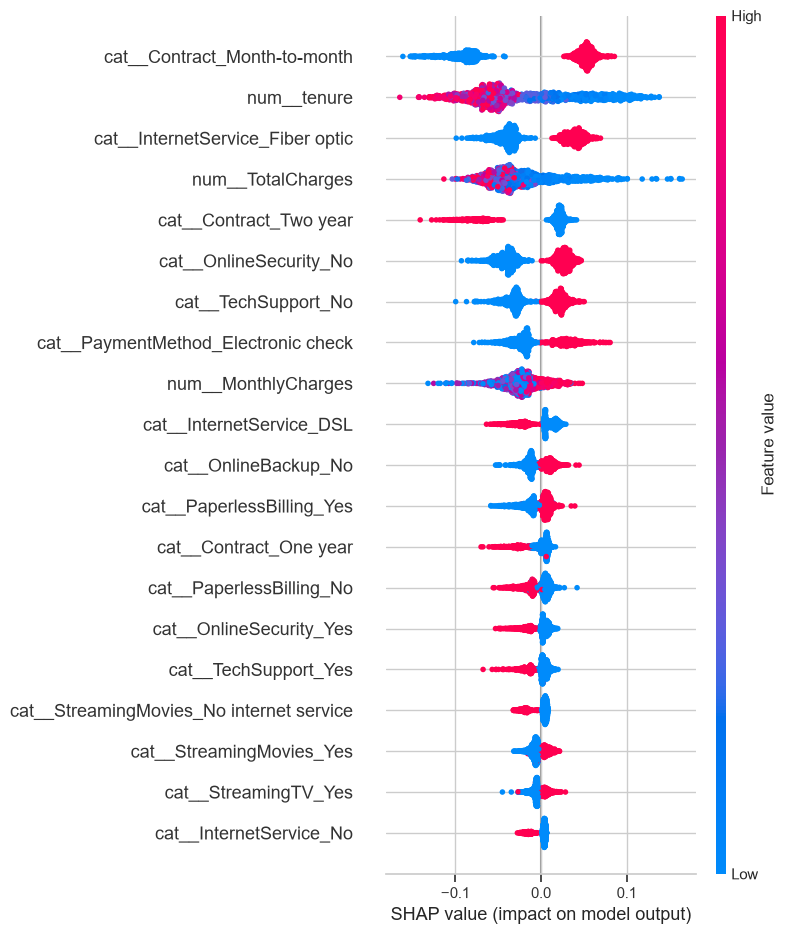

In [30]:
shap.summary_plot(
    shap_churn_values,
    X_test_transformed,
    feature_names=feature_names,
    show=True
)

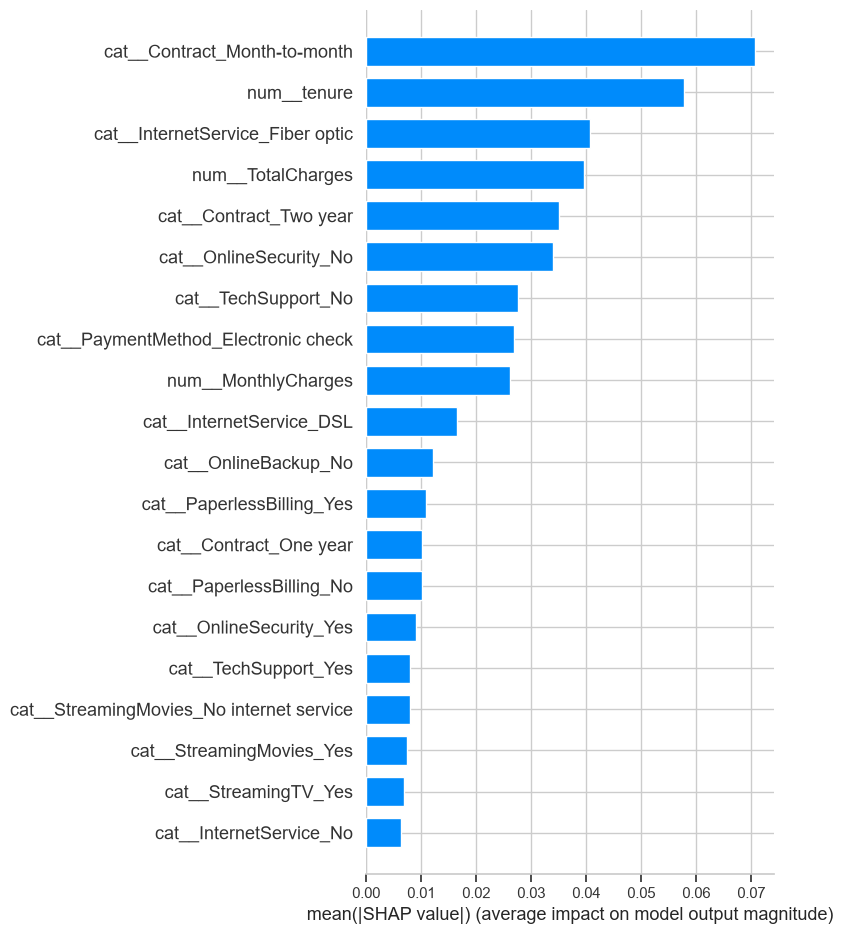

In [31]:
shap.summary_plot(
    shap_churn_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

In [32]:
mean_abs_shap = np.abs(
    shap_churn_values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": mean_abs_shap
}).sort_values(
    "MeanAbsSHAP",
    ascending=False
)

shap_importance.head(20)

,Feature,MeanAbsSHAP
36,cat__Contract_Month-to-month,0.070592
1,num__tenure,0.057803
16,cat__InternetService_Fiber optic,0.040721
3,num__TotalCharges,0.039522
38,cat__Contract_Two year,0.035007
18,cat__OnlineSecurity_No,0.033865
27,cat__TechSupport_No,0.027656
43,cat__PaymentMethod_Electronic check,0.026906
2,num__MonthlyCharges,0.026048
15,cat__InternetService_DSL,0.016545


In [33]:
importance_comparison = (
    feature_importance
    .merge(
        shap_importance,
        on="Feature",
        how="outer"
    )
    .sort_values(
        "MeanAbsSHAP",
        ascending=False
    )
)

importance_comparison.head(20)

,Feature,Importance,MeanAbsSHAP
0,cat__Contract_Month-to-month,0.072302,0.070592
44,num__tenure,0.132329,0.057803
9,cat__InternetService_Fiber optic,0.028522,0.040721
43,num__TotalCharges,0.142474,0.039522
2,cat__Contract_Two year,0.036527,0.035007
17,cat__OnlineSecurity_No,0.036642,0.033865
36,cat__TechSupport_No,0.031064,0.027656
26,cat__PaymentMethod_Electronic check,0.029037,0.026906
41,num__MonthlyCharges,0.122295,0.026048
8,cat__InternetService_DSL,0.010683,0.016545


In [34]:
customer_index = 0

print("Customer information:")
display(X_test.iloc[[customer_index]])

print("\nActual churn:", y_test.iloc[customer_index])
print(
    "Predicted churn probability:",
    rf_probabilities[customer_index]
)

Customer information:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2



Actual churn: 0
Predicted churn probability: 0.0


In [35]:
print("Actual churn:", y_test.iloc[customer_index])
print(
    "Predicted churn probability:",
    rf_probabilities[customer_index]
)

print("\nExpected value:")
print(explainer.expected_value)

print("\nSHAP contribution shape:")
print(shap_churn_values[customer_index].shape)

Actual churn: 0
Predicted churn probability: 0.0

Expected value:
[0.49960774 0.50039226]

SHAP contribution shape:
(45,)


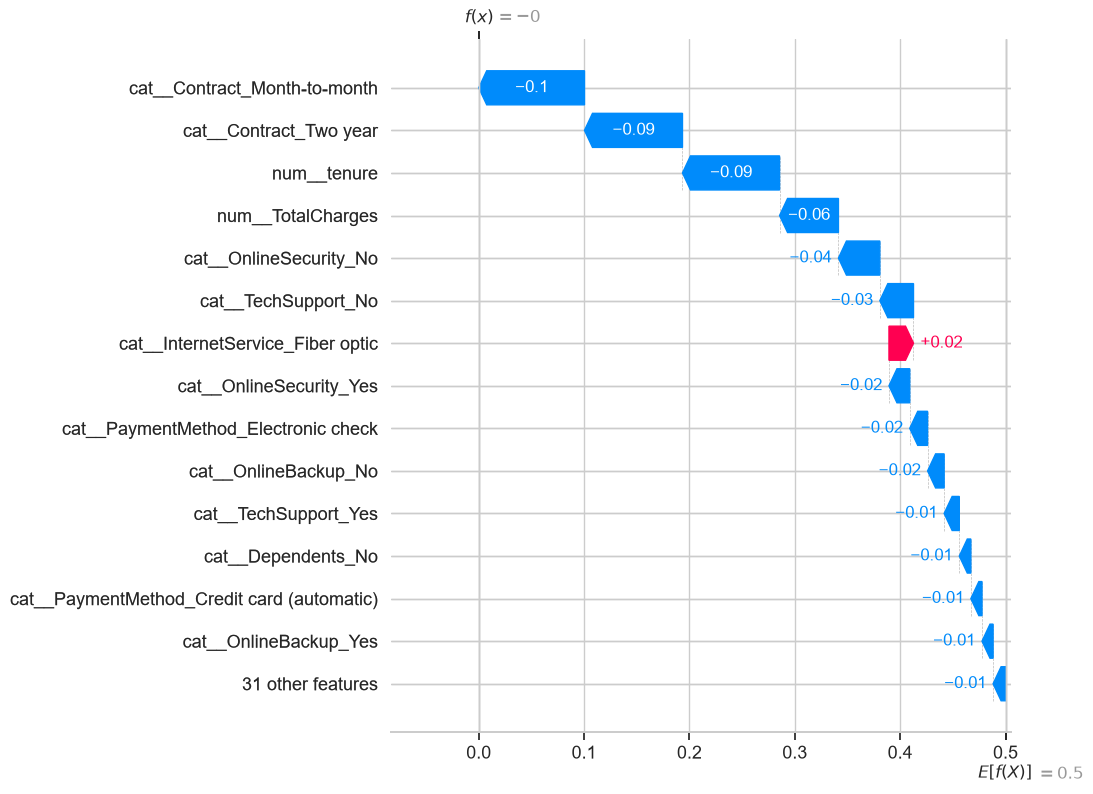

<Figure size 640x480 with 0 Axes>

In [36]:
customer_index = 0

base_value = explainer.expected_value[1]

shap.plots._waterfall.waterfall_legacy(
    base_value,
    shap_churn_values[customer_index],
    feature_names=feature_names,
    max_display=15
)

plt.tight_layout()
plt.show()

In [37]:
best_model = model_results.sort_values(
    "ROC_AUC",
    ascending=False
).iloc[0]

print("=" * 60)
print("BASELINE MODELING SUMMARY")
print("=" * 60)

print(f"Best model by ROC-AUC: {best_model['Model']}")
print(f"Accuracy:  {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall:    {best_model['Recall']:.4f}")
print(f"F1 Score:  {best_model['F1']:.4f}")
print(f"ROC-AUC:   {best_model['ROC_AUC']:.4f}")

BASELINE MODELING SUMMARY
Best model by ROC-AUC: Logistic Regression
Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1 Score:  0.6040
ROC-AUC:   0.8419


In [38]:
print("""
Baseline machine learning and SHAP analysis completed.

This notebook covered:

1. Dataset preparation for predictive modeling.
2. Stratified train/test splitting.
3. Logistic Regression baseline.
4. Random Forest baseline.
5. Classification performance evaluation.
6. Confusion matrix analysis.
7. ROC-AUC comparison.
8. Random Forest feature importance.
9. SHAP global explainability.
10. Individual customer-level explanation.

The next stage is model probability calibration.
""")


Baseline machine learning and SHAP analysis completed.

This notebook covered:

1. Dataset preparation for predictive modeling.
2. Stratified train/test splitting.
3. Logistic Regression baseline.
4. Random Forest baseline.
5. Classification performance evaluation.
6. Confusion matrix analysis.
7. ROC-AUC comparison.
8. Random Forest feature importance.
9. SHAP global explainability.
10. Individual customer-level explanation.

The next stage is model probability calibration.

